# Gunnuhver Fiber Bragg Grating Accelerometer

This notebook investigates **Fiber Bragg Grating** (FBG) accelerometer recordings from the Gunnuhver area during the earthquake sequence of 30 - 31 July 2024. The FBG data are processed by selecting the relevant time period, resampling to 100 Hz, applying a band-pass filter, and removing the linear trend.

The processed signal is compared with the local earthquake catalog to examine the sensor response to seismic events. The analysis includes waveform visualizations, detailed event windows, spectrograms, and a map showing the earthquake locations and their temporal distribution around Gunnuhver.

## Import Python packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from scipy.signal import detrend, spectrogram, medfilt2d
from obspy.signal.filter import bandpass
from tqdm import tqdm

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as colors
from matplotlib.patches import ConnectionPatch

## FBG data processing

### Import the FBG data

In [2]:
path ='../data/gunnuhver/FBG/'
data30 = xr.open_dataset(path+'FBG_HSV_2024.07.30T00.00.00.000.nc')
data31 = xr.open_dataset(path+'FBG_HSV_2024.07.31T00.00.00.000.nc')

data = xr.concat([data30, data31], dim='Time')

### Select the specific period

In [3]:
data = data.sel(Time=slice('2024-07-30T21:00', '2024-07-31T06:00'))

### Calculate sampling frequency

In [4]:
fs = float(data.Time.size)//(data.Time[-1].values-data.Time[0].values).astype('timedelta64[s]').astype(float)

In [5]:
print('Sampling frequency: ', fs, 'Hz')

Sampling frequency:  200.0 Hz


### Select the 4th FBG

In [6]:
n = 3
FBG = data.Wavelength_nm[n,:] - data.Wavelength_nm[n,:].median()

### Resampling at 100Hz

In [7]:
FBG = FBG.to_dataframe().resample("10ms").median()

### Select the first 1000 values, band-pass filter and detrend

In [8]:
time = FBG.index[1000:]
FBG = FBG.to_numpy().flatten()
FBGfilt = bandpass(FBG, 1, 45, 100)
FBGfilt = detrend(FBGfilt[1000:])


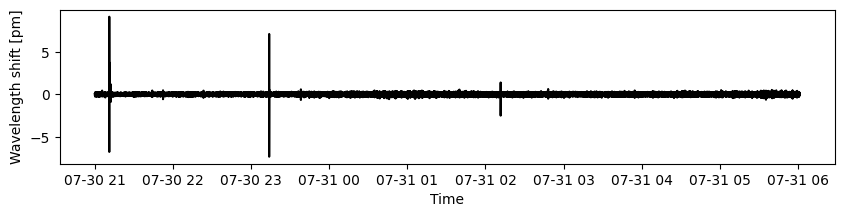

In [9]:
plt.figure(figsize=(10,2))
plt.plot(time, FBGfilt*1000, color='k', label='FBG')
plt.ylabel('Wavelength shift [pm]')
plt.xlabel('Time')
plt.show()

## Import earthquake catalog

In [10]:
earthquake = pd.read_csv('../map/gunn_earthquake_30072024.csv')
etime = np.array(earthquake['time'])
etime = etime.astype('datetime64[s]')

In [11]:
dsTime = etime - np.datetime64('2024-07-30T21:00:00')

In [12]:
dsTime = dsTime.astype(int)

## Build the summary plot

In [13]:
import rasterio

import cartopy.crs as ccrs

/tmp/ipykernel_564522/1857380766.py:127: RuntimeWarning: divide by zero encountered in log10
  spectro = ax4.pcolormesh(T,F, 10*np.log10(medfilt2d(Sxx, )).T, vmax=-80, vmin=-110, cmap='inferno')


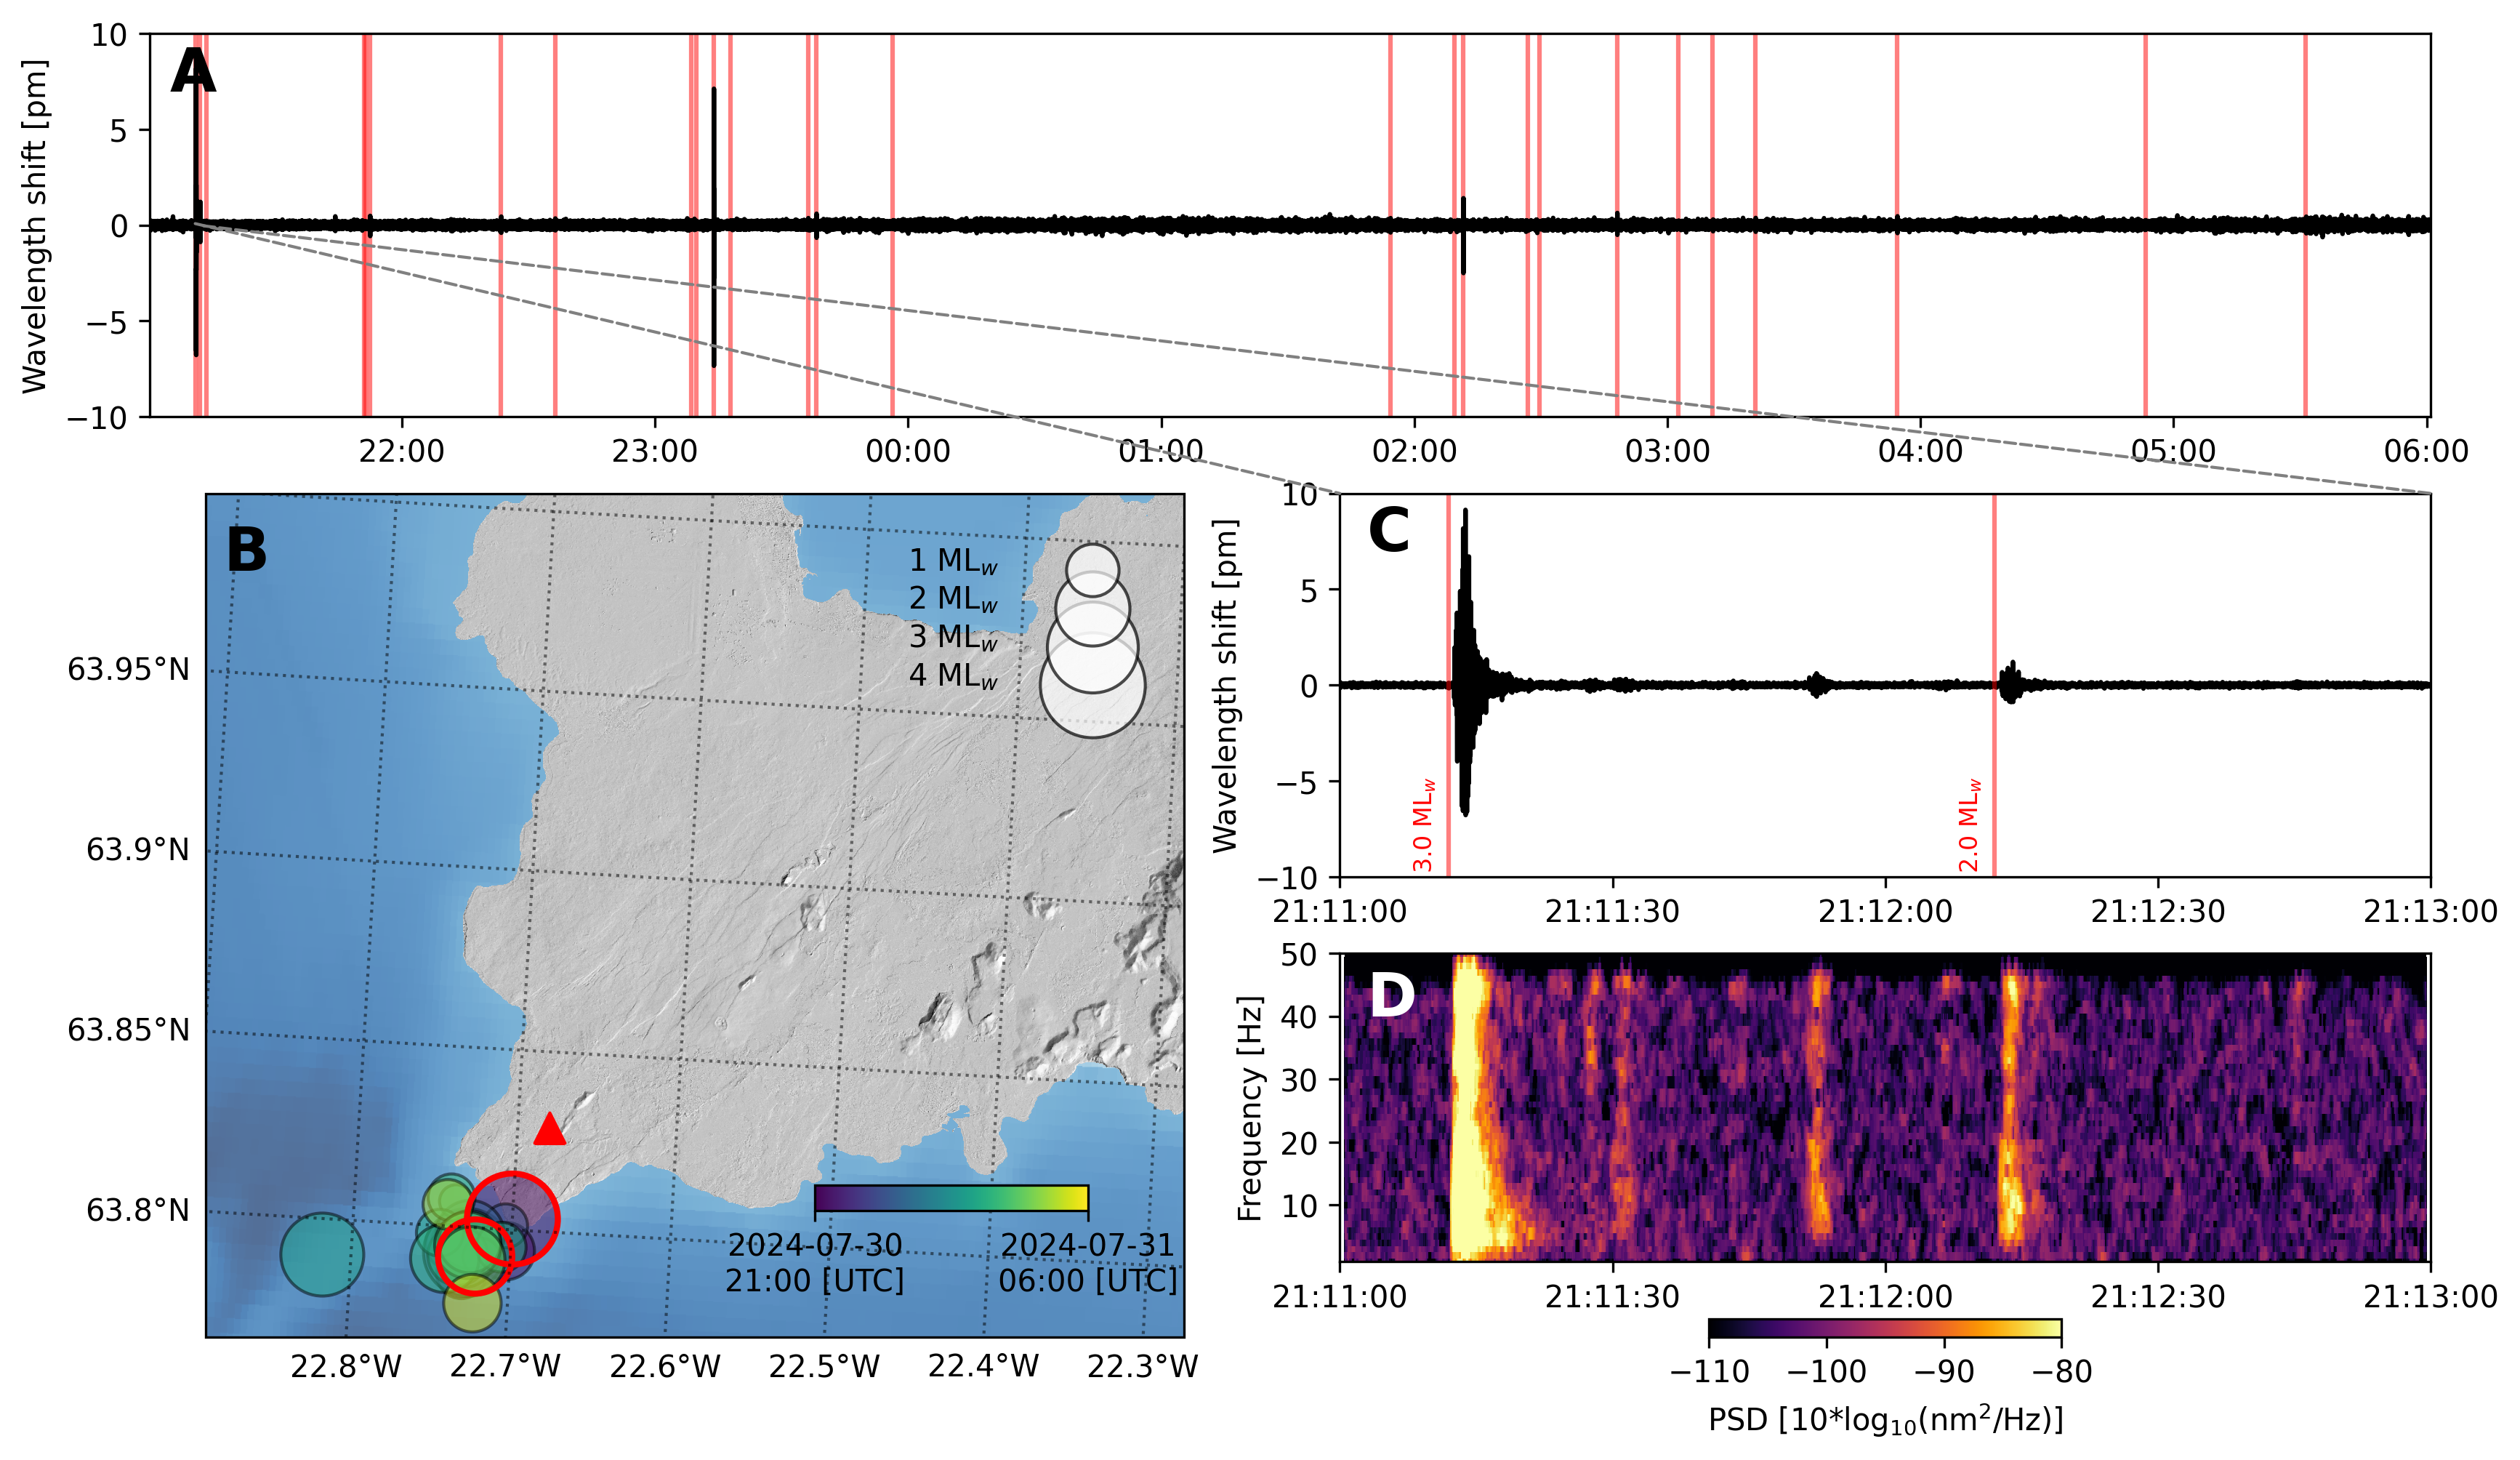

In [14]:
# Load the GeoTIFF file
geotiff_path = '../map/shadows_gunn_1_20m.tif'
with rasterio.open(geotiff_path) as src:
    img = src.read(1)
    img = np.where(img == -9999, np.nan, img)
    transform = src.transform
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

geotiff_path = '../map/gebco_2023_n70.0_s60.0_w-30.0_e-10.0.tif'
with rasterio.open(geotiff_path) as src:
    oce = src.read(1)
    oce = np.where(oce == -9999, np.nan, oce)
    transform_oce = src.transform
    extent_oce = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]


geotiff_path = '../map/shadows_gunn_2_20m.tif'
with rasterio.open(geotiff_path) as src:
    img2 = src.read(1)
    img2 = np.where(img == -9999, np.nan, img)
    transform2 = src.transform
img = img+img2

# Plot the GeoTIFF file using Cartopy

fig = plt.figure(figsize=(27/2, 21/2), dpi=300)

norm = colors.Normalize(vmin=0, vmax=3600*9)

ax = plt.subplot2grid((4, 4), (1, 0), colspan=2, rowspan=2, projection=ccrs.epsg(8088))
ax.set_extent([-22.89, -22.3, 63.78, 64.], crs=ccrs.PlateCarree())

# Display the image
ax.imshow(img, origin='upper', transform=ccrs.epsg(8088), extent=extent, cmap='gray', zorder=.99)
ax.imshow(oce, origin='upper', transform=ccrs.PlateCarree(), extent=extent_oce, cmap='Blues_r', zorder=.98, alpha=.7)
ax.scatter(-22.68, 63.829, color='red', marker='^', transform=ccrs.PlateCarree(), zorder=5, s=100)  # Add a red dot at a specific location
ax.scatter(earthquake.longitude, earthquake.latitude, c=dsTime, edgecolors='k', s=earthquake.magnitude*300, alpha=.5, transform=ccrs.PlateCarree(), norm=norm)  # Add a red dot at a specific location
ax.scatter(earthquake.longitude[:2], earthquake.latitude[:2], c='None', edgecolors='r', s=earthquake.magnitude[:2]*300, alpha=1, transform=ccrs.PlateCarree(), linewidth=2)  # Add a red dot at a specific location



# Add gridlines and map features
gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=1, color='black', alpha=0.5, linestyle=':', draw_labels=True, x_inline=False, y_inline=False)
gl.top_labels = gl.right_labels = False
#ax.add_feature(cfeature.BORDERS, linestyle=':')
#ax.add_feature(cfeature.COASTLINE)

ax = plt.subplot2grid((4, 4), (1, 0), colspan=2, rowspan=2)
earthcake = ax.scatter(earthquake.longitude, earthquake.latitude, c=dsTime, visible=False, norm=norm)
ax.text(-22.85, 63.98,'B', fontsize=20, fontweight='bold')

ax.set_xlim(-22.89, -22.3)
ax.set_ylim(63.78, 64.)
for i in range(1,5) :
    ax.scatter(-22.38, 63.99-i/100, s=i*300, facecolors='white', edgecolors='k', linewidth=1, alpha=.7, zorder = 5-i)
    ax.text(-22.48, 63.99-i/100, f'{i} ML$_w$', fontsize=10, color='k', zorder = 5-i)
#ax.get_yaxis().set_visible(False)
#ax.get_xaxis().set_visible(False)
plt.axis('off')
cax = ax.inset_axes([0.61, 0.15, 0.25, 0.03])
clb = fig.colorbar(earthcake, cax=cax, orientation='horizontal')

clb.set_ticks(ticks=[0, 9*3600], labels=['2024-07-30\n21:00 [UTC]','2024-07-31\n06:00 [UTC]'])

idex = np.argmin(np.abs(time-np.datetime64("2024-07-30T21:11:00")))
nsec = 120

ax2 = plt.subplot2grid((4, 4), (0, 0), colspan=4, rowspan=1)
ax2.text(np.datetime64('2024-07-30T21:05'), 7,'A', fontsize=20, fontweight='bold')
ax2.xaxis_date()
ax2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))
ax2.plot(time, FBGfilt*1000, c='k')
for EQ in etime :
    ax2.axvline(EQ, c='r', alpha=.5, zorder=0.1)
ax2.set_ylabel('Wavelength shift [pm]')
ax2.set_xlim(time[0],time[-1])
ax2.set_ylim(-10,10)

ax3 = plt.subplot2grid((4, 4), (1, 2), colspan=2, rowspan=1)
ax3.xaxis_date()
ax3.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M:%S'))
ax3.plot(time[idex:int(idex+100*nsec)], FBGfilt[idex:int(idex+100*nsec)]*1000, c='k')
ax3.text(np.datetime64('2024-07-30T21:11:03'), 7,'C', fontsize=20, fontweight='bold')
ax3.set_ylabel('Wavelength shift [pm]')
ax3.set_xlim(time[idex],time[int(idex+100*nsec)])
ax3.set_ylim(-10,10)
#ax3.set_xticks([])
xy = (mdates.date2num(time[idex]), FBGfilt[idex]*1000)
xy2 = (mdates.date2num(time[idex]), 10)
con1 = ConnectionPatch(
    xyA=xy,
    xyB=xy2,
    coordsA="data",
    coordsB="data",
    axesA=ax2,
    axesB=ax3,
    color="grey",
    linestyle='--'
)

fig.add_artist(con1) 

xy = (mdates.date2num(time[int(idex+100*nsec)]), FBGfilt[int(idex+100*nsec)]*1000)
xy2 = (mdates.date2num(time[int(idex+100*nsec)]), 10)

con2 = ConnectionPatch(
    xyA=xy,
    xyB=xy2,
    coordsA="data",
    coordsB="data",
    axesA=ax2,
    axesB=ax3,
    color="grey",
    linestyle='--'
)

fig.add_artist(con2) 


ax4= plt.subplot2grid((4, 4), (2, 2), colspan=2, rowspan=1)
ax4.xaxis_date()
ax4.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M:%S'))

f,t, Sxx = spectrogram(FBGfilt[idex:int(idex+100*nsec)], 100, nperseg=int(100), noverlap=int(90))
t = time[idex] + np.timedelta64(1, 'ms')*(t*1000).astype(int)
F,T = np.meshgrid(f,t)
spectro = ax4.pcolormesh(T,F, 10*np.log10(medfilt2d(Sxx, )).T, vmax=-80, vmin=-110, cmap='inferno')
ax4.text(np.datetime64('2024-07-30T21:11:03'), 40,'D', fontsize=20, fontweight='bold', color='w')

ax4.set_ylabel('Frequency [Hz]')
ax4.set_ylim(1,50)
ax4.set_xlim(time[idex],time[int(idex+100*nsec)])
fig.colorbar(spectro, ax=ax4, orientation='horizontal', label='PSD [10*log$_{10}$(nm$^2$/Hz)]', fraction=0.046)
for i in range(2):
    ax3.axvline(etime[i]+int(3), c='r', alpha=.5) #time lag correction due to computer
    ax3.text(etime[i]-int(1), -9.5, '%.1f ML$_{w}$'%earthquake.magnitude[i], rotation=90, fontsize=8, color='r')

ticktime = np.datetime64('2024-07-30T21:11:00', 's') + np.arange(150, step=30) 
ax4.set_xticks(ticktime)
ax3.set_xticks(ticktime)
#plt.colorbar(earthcake, label='Earthquake time')
plt.savefig('../plots/gunn_earthquake_30072024.png', dpi=600, bbox_inches='tight', transparent=True)

plt.show()
